# Problems in Neural Network Training

In dieser Vorlesung betrachten wir Probleme die beim Training Neuronaler Netze auftreten können. Dies sind das Problem des Vanishing Gradients und das Problem des Overfittings.

## Overfitting

Overfitting ist ein großes Problem bei neuronalen Netzen, speziell bei tiefen Netzen mit vielen Parametern sowie hoch-dimensionalen Merkmalen.

Wie man dem Problem begegnet, betrachten wir betrachten anhand der Daten aus der Kaggle-Challenge Dont Overfit II: https://www.kaggle.com/c/dont-overfit-ii

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
df = pd.read_csv("./data/dont_overfit2_train.csv", index_col="id")
X = df.drop(columns=["target"])
y = df.filter(["target"])
X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, 
                                                        test_size=0.2, random_state=42)


In [4]:
print(X_train.shape)

print(y_train.shape)

(200, 300)
(200, 1)


In [5]:
model = tf.keras.Sequential()

model.add(tf.keras.layers.Dense(64, activation='relu', input_dim=300))
model.add(tf.keras.layers.Dense(32, activation='relu'))
model.add(tf.keras.layers.Dense(8, activation='relu'))
model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, batch_size=64, 
                    epochs=100,  verbose=1)

Epoch 1/100
4/4 [==============================] - 0s 1ms/step - loss: 0.7059 - accuracy: 0.5300
Epoch 2/100
4/4 [==============================] - 0s 692us/step - loss: 0.5545 - accuracy: 0.6950
Epoch 3/100
4/4 [==============================] - 0s 581us/step - loss: 0.4799 - accuracy: 0.7450
Epoch 4/100
4/4 [==============================] - 0s 611us/step - loss: 0.4224 - accuracy: 0.8100
Epoch 5/100
4/4 [==============================] - 0s 764us/step - loss: 0.3709 - accuracy: 0.8550
Epoch 6/100
4/4 [==============================] - 0s 800us/step - loss: 0.3273 - accuracy: 0.9100
Epoch 7/100
4/4 [==============================] - 0s 716us/step - loss: 0.2886 - accuracy: 0.9500
Epoch 8/100
4/4 [==============================] - 0s 725us/step - loss: 0.2533 - accuracy: 0.9550
Epoch 9/100
4/4 [==============================] - 0s 876us/step - loss: 0.2229 - accuracy: 0.9600
Epoch 10/100
4/4 [==============================] - 0s 839us/step - loss: 0.1959 - accuracy: 0.9600
Epoch 11/10

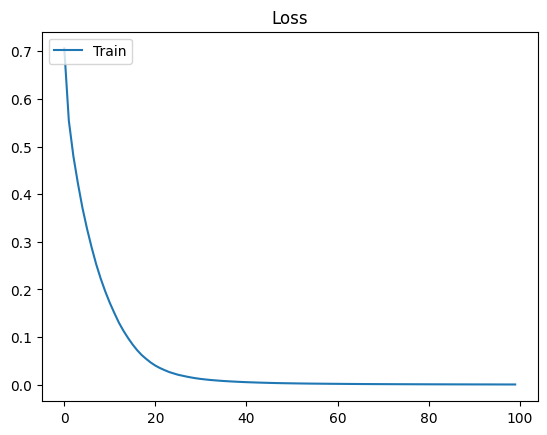

In [6]:
plt.plot(history.history['loss'])
plt.title('Loss')
plt.legend(['Train'], loc='upper left')
plt.show()

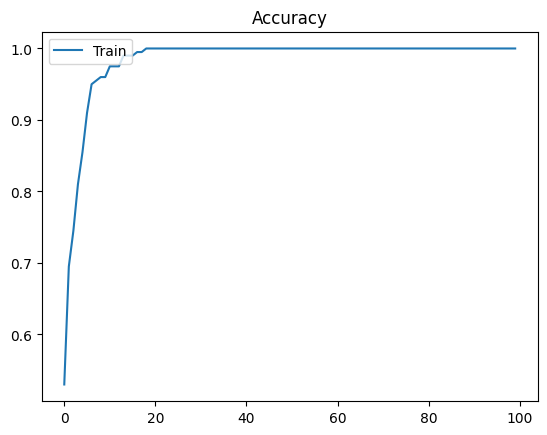

In [7]:
plt.plot(history.history['accuracy'])
plt.title('Accuracy')
plt.legend(['Train'], loc='upper left')
plt.show()

In [8]:
model = tf.keras.Sequential()

model.add(tf.keras.layers.Dense(64, activation='relu', input_dim=300))
model.add(tf.keras.layers.Dense(32, activation='relu'))
model.add(tf.keras.layers.Dense(8, activation='relu'))
model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, batch_size=64, validation_split=0.25,
                    epochs=100,  verbose=0)

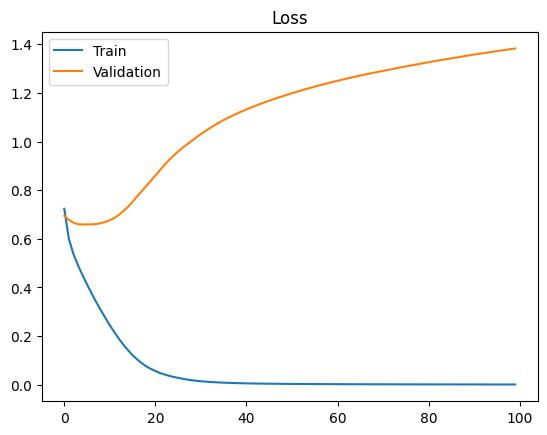

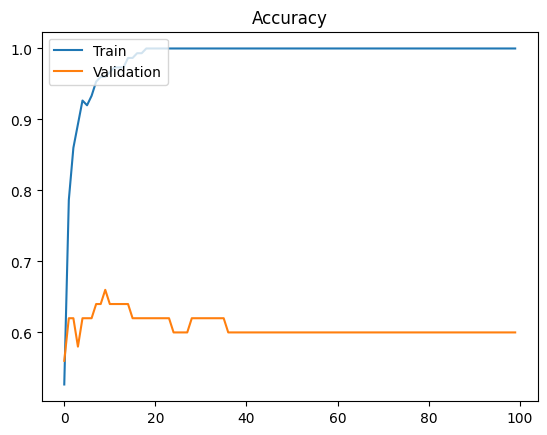

In [9]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

### Regularisierung

In [10]:
model_reg = tf.keras.Sequential()

model_reg.add(tf.keras.layers.Dense(32, kernel_regularizer=tf.keras.regularizers.l2(0.01),activation='relu', input_dim=300))
model_reg.add(tf.keras.layers.Dense(16, kernel_regularizer=tf.keras.regularizers.l2(0.01),activation='relu'))
model_reg.add(tf.keras.layers.Dense(8, kernel_regularizer=tf.keras.regularizers.l2(0.01),activation='relu'))
model_reg.add(tf.keras.layers.Dense(1, kernel_regularizer=tf.keras.regularizers.l2(0.01),activation='sigmoid'))
model_reg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_reg = model_reg.fit(X_train, y_train, batch_size=64, 
                    epochs=100, validation_split=0.25, verbose=0)

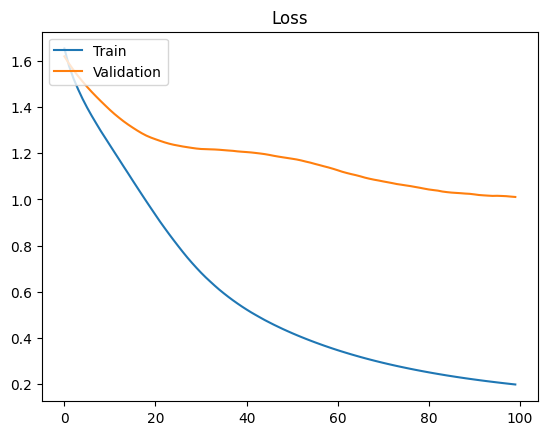

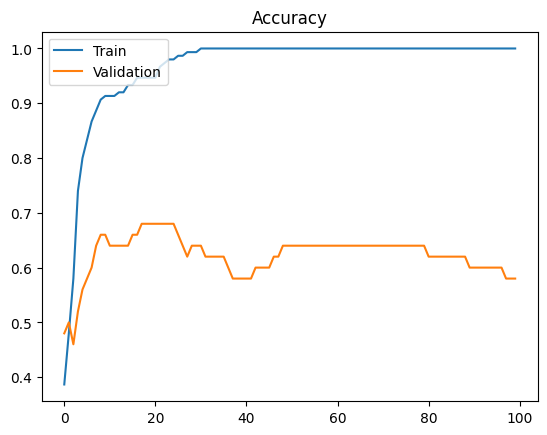

In [11]:
plt.plot(history_reg.history['loss'])
plt.plot(history_reg.history['val_loss'])
plt.title('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.plot(history_reg.history['accuracy'])
plt.plot(history_reg.history['val_accuracy'])
plt.title('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

### Dropout

In [12]:
model_do = tf.keras.Sequential()

model_do.add(tf.keras.layers.Dense(32, activation='relu', input_dim=300))
model_do.add(tf.keras.layers.Dropout(rate=0.4))
model_do.add(tf.keras.layers.Dense(16, activation='relu'))
model_do.add(tf.keras.layers.Dropout(rate=0.4))
model_do.add(tf.keras.layers.Dense(8, activation='relu'))
model_do.add(tf.keras.layers.Dropout(rate=0.4))

model_do.add(tf.keras.layers.Dense(1, activation='sigmoid'))
model_do.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_do = model_do.fit(X_train, y_train, batch_size=64, 
                    epochs=100, validation_split=0.25, verbose=0)

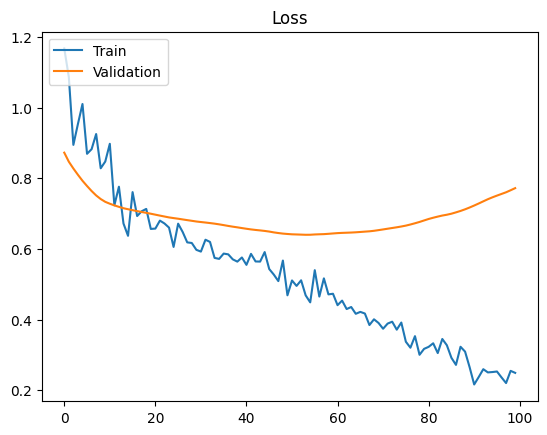

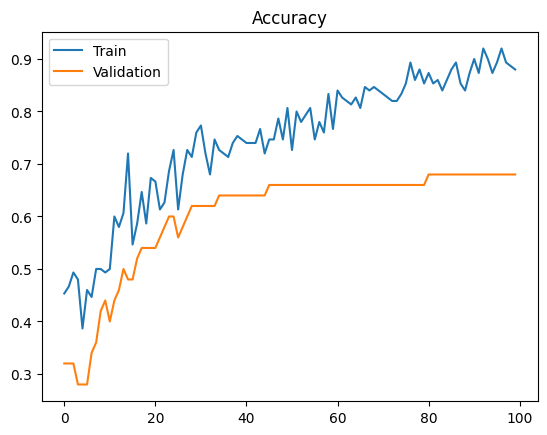

In [13]:
plt.plot(history_do.history['loss'])
plt.plot(history_do.history['val_loss'])
plt.title('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.plot(history_do.history['accuracy'])
plt.plot(history_do.history['val_accuracy'])
plt.title('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

### Early stopping

In [14]:
model_does = tf.keras.Sequential()

model_does.add(tf.keras.layers.Dense(32, activation='relu', input_dim=300))
model_does.add(tf.keras.layers.Dropout(rate=0.4))
model_does.add(tf.keras.layers.Dense(16, activation='relu'))
model_does.add(tf.keras.layers.Dropout(rate=0.4))
model_does.add(tf.keras.layers.Dense(8, activation='relu'))
model_does.add(tf.keras.layers.Dropout(rate=0.4))

model_does.add(tf.keras.layers.Dense(1, activation='sigmoid'))
model_does.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3
)

history_does = model_does.fit(
    X_train, y_train,
    batch_size=64,
    epochs=100,
    callbacks=[es_callback],  # Stop training process earlier
    validation_split=0.25,verbose=0
)

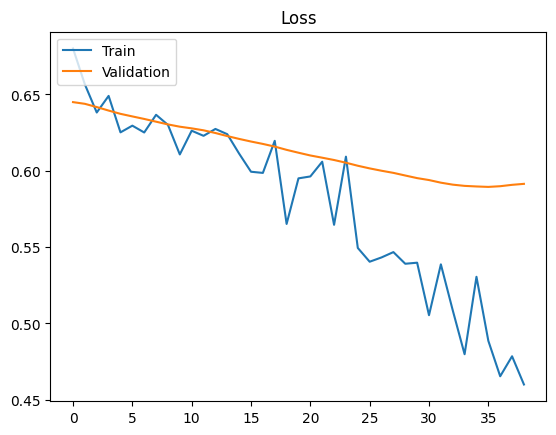

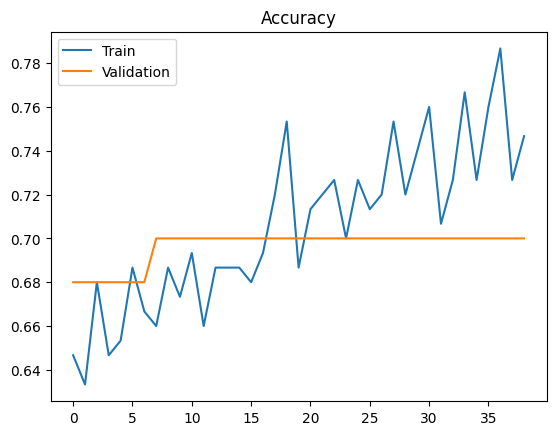

In [15]:
plt.plot(history_does.history['loss'])
plt.plot(history_does.history['val_loss'])
plt.title('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.plot(history_does.history['accuracy'])
plt.plot(history_does.history['val_accuracy'])
plt.title('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()